In [1]:
import torch
import torch.nn as nn
import numpy as np
import scipy.io
from matplotlib import pyplot as plt
import matplotlib.animation as animation

## Generating Data

In [2]:
# Define the coordinates for the square's corners
x_min, y_min = 0, 0  # Lower-left corner
x_max, y_max = 1.0, 1.0  # Upper-right corner for a square with side length 1
t_min, t_max = 0, 20

In [3]:
##Generating Data
a=0.1
gamma=1
beta=0.5
eps=0.01
delta=0.0


dx=0.5
dt=0.1

diff = 0.5 ## diffusion coefficient
endtime=200 ## length of simulation in physical time units
nend=int(np.ceil(endtime/dt)) ## length of simulation in time steps
# outputevery=5  ##save u variable for display every this many time units
# nout=np.ceil(endtime/outputevery) ##number of times to output
# kout=1 ##index for output
nx = 100 ##2d square length in gridpoints; physical length is nx * dx


u=np.zeros((nx,nx), dtype= float); ##fast "voltage"-like variable
v=np.zeros((nx,nx), dtype=float); ##slow recovery variable
print(u.shape, v.shape, np.arange(np.ceil(nx/2), dtype = int).shape)


# u[0:25, 0:25] = 0.5



(100, 100) (100, 100) (50,)


In [4]:
radius = nx // 4

for i in range(nx):
    for j in range(nx):
        if i**2 + j**2 <= radius**2:
            u[i, j] = 0.5

In [5]:
radius = nx // 4

x = np.arange(nx)
y = np.arange(nx)
X, Y = np.meshgrid(x, y, indexing='ij')

mask = X**2 + Y**2 <= radius**2
u[mask] = 0.5

In [6]:
v1=v.copy()
u1 =u.copy()
training_points = np.zeros((100,100,100))
training_points_v = np.zeros((100,100,100))

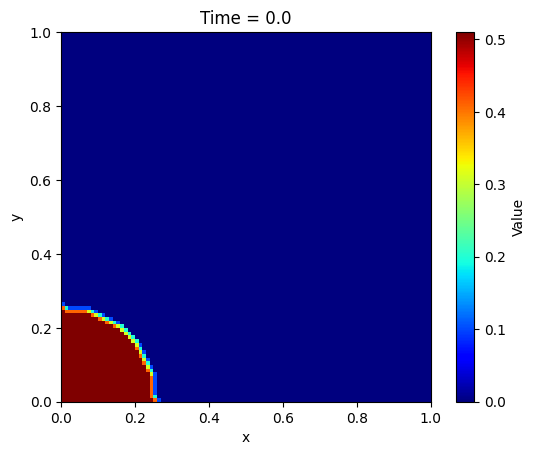

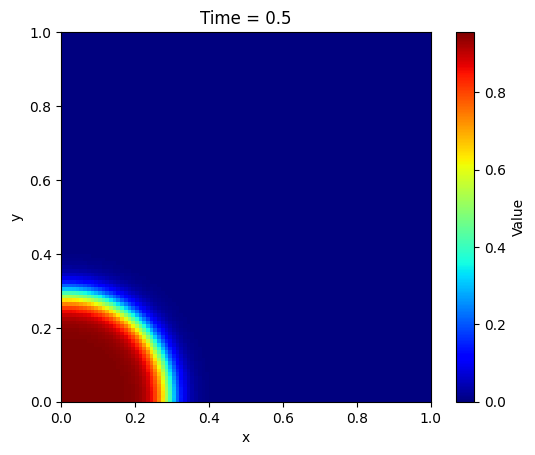

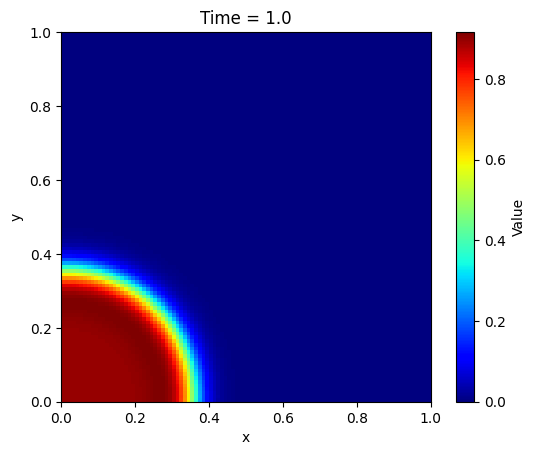

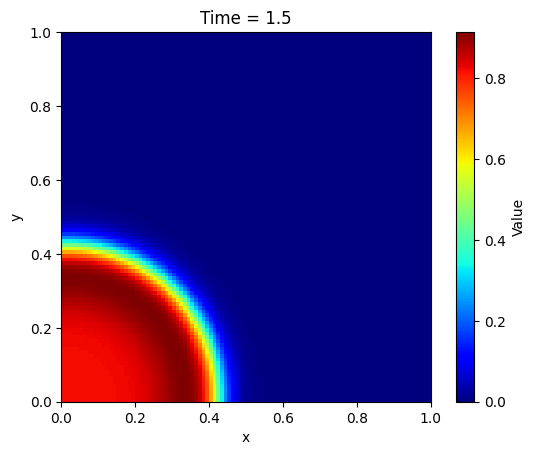

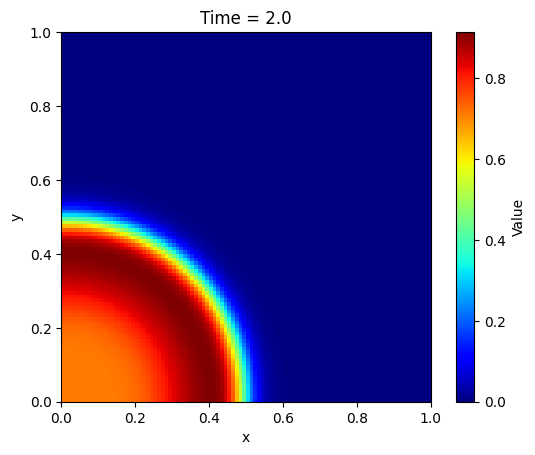

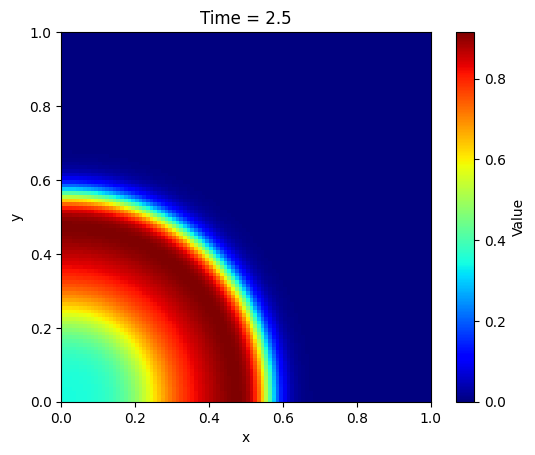

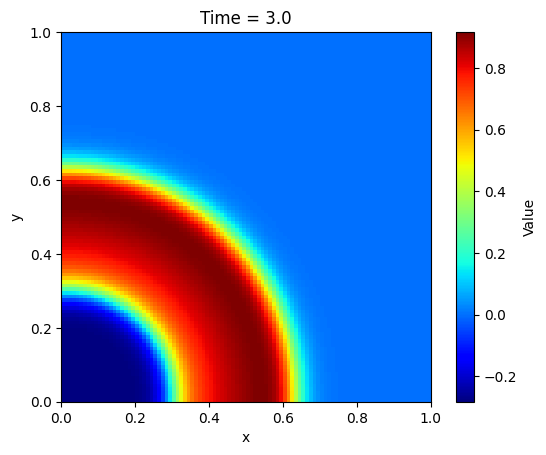

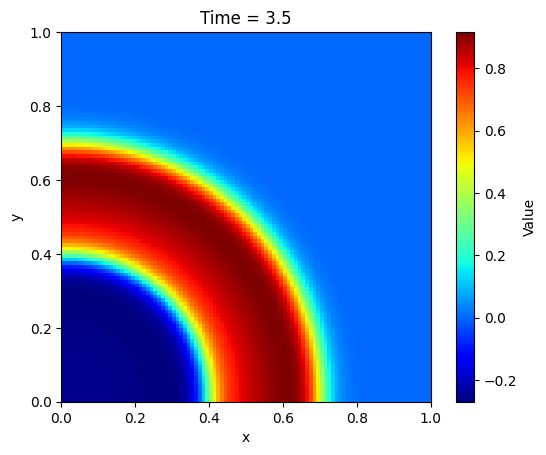

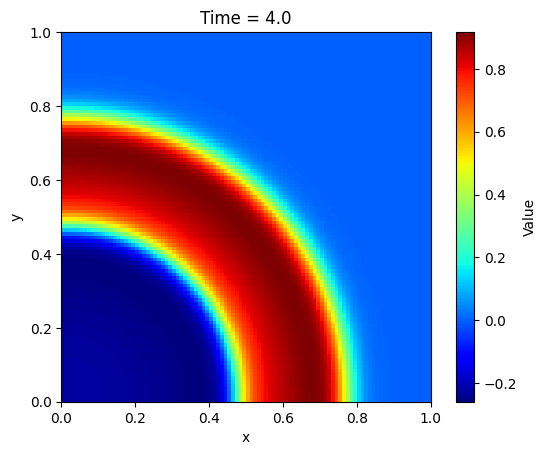

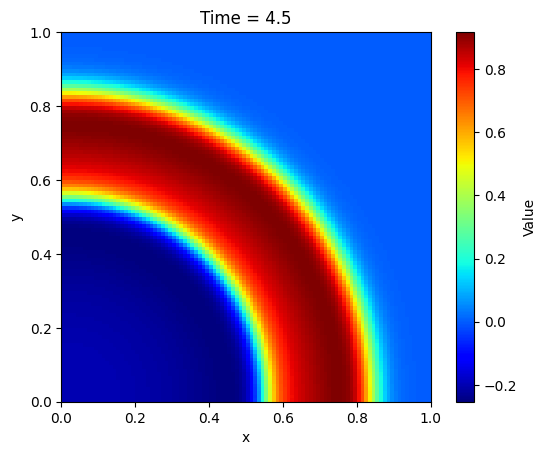

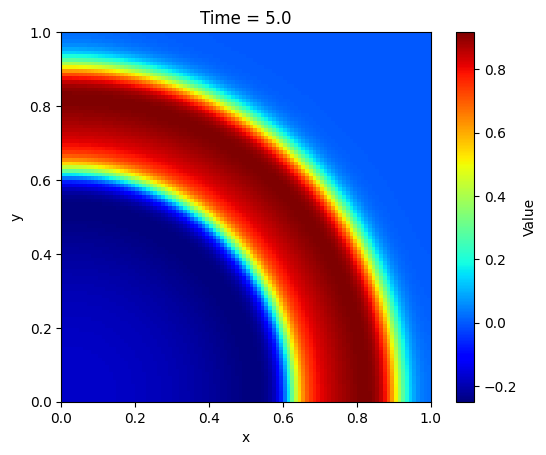

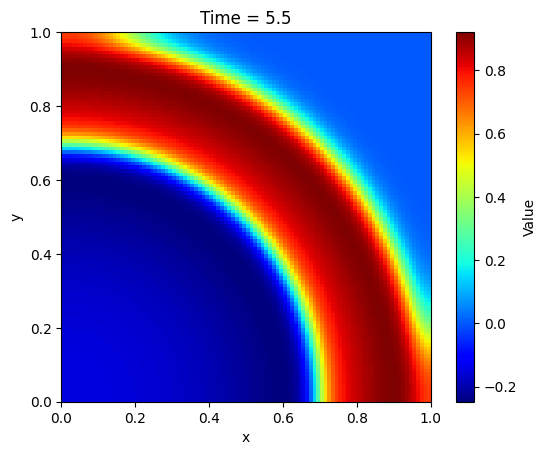

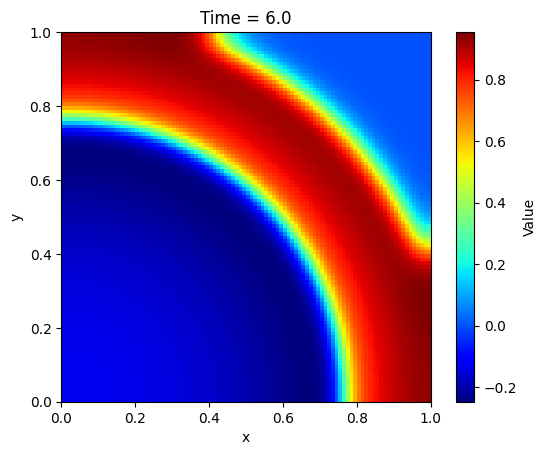

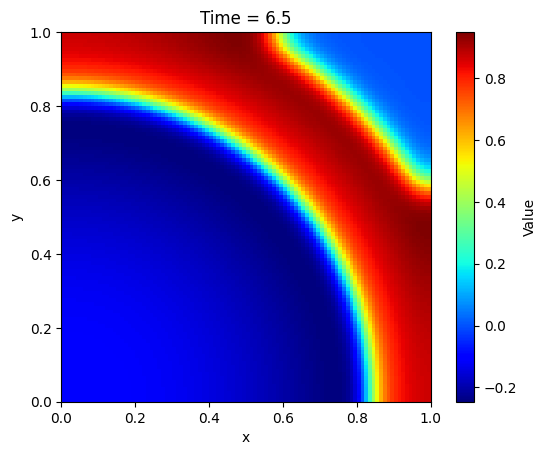

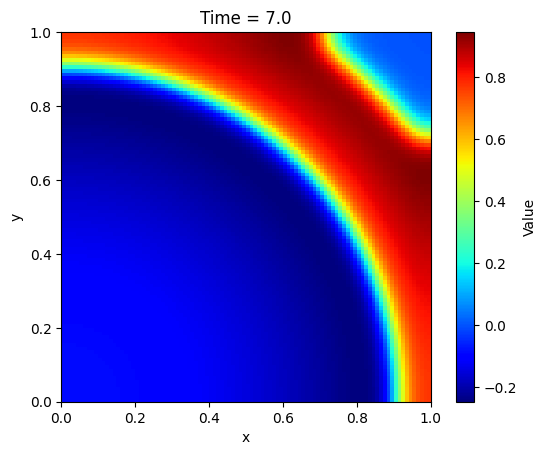

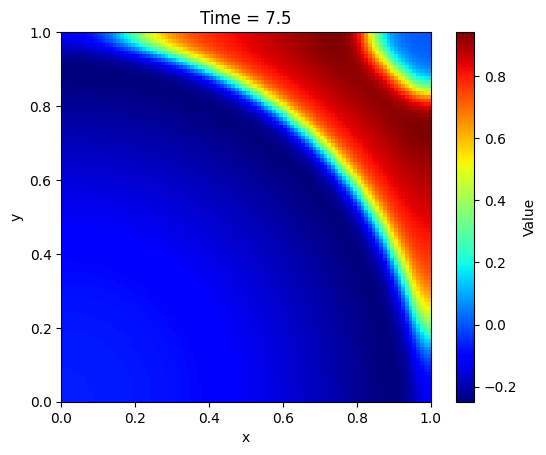

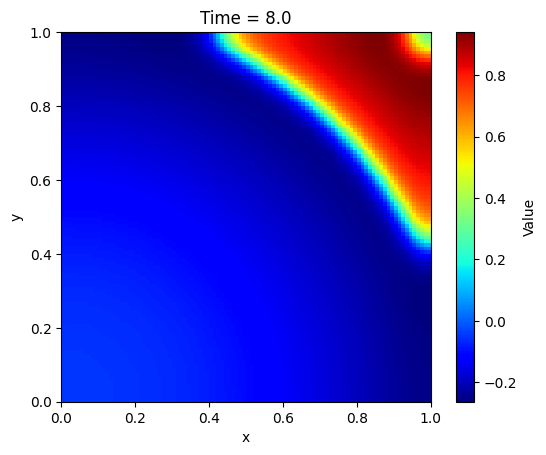

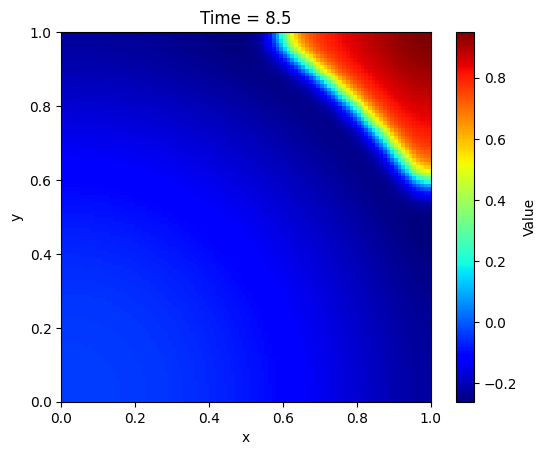

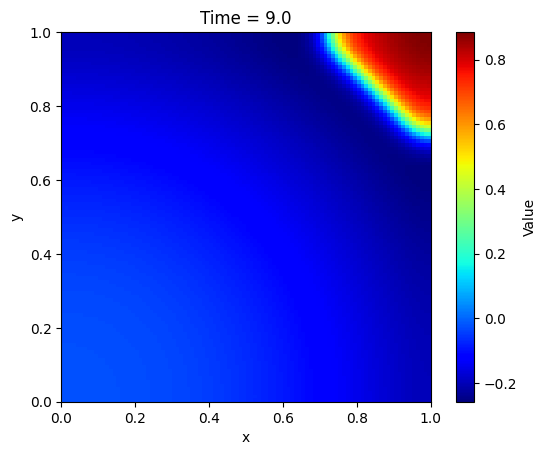

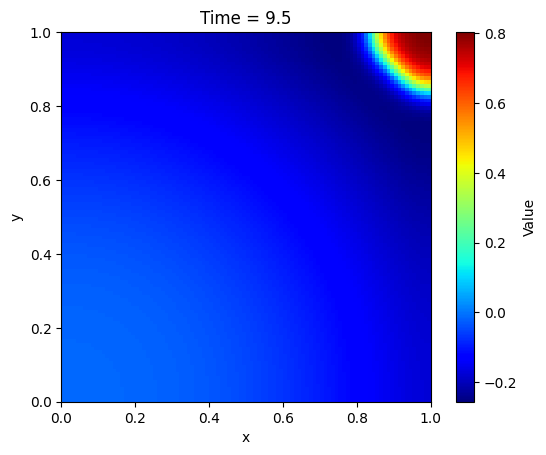

In [7]:
## Generating data
for ntime in range(nend): # 500 is the number of timesteps

    uold = u1.copy()
    vold = v1.copy()
    dv1 = eps*(beta*uold - gamma*vold -delta)
    du1 = (a-uold)*(uold-1)*uold-vold


    diff_x = np.zeros((nx, nx), dtype = float)
    diff_y = np.zeros((nx, nx), dtype = float)
    diff_x[0, :] = 2*(uold[2, :] - uold[1, :])
    diff_x[nx-1, :] = 2*(-uold[nx-1, :] + uold[nx-2, :])
    diff_x[1:-1, :] = uold[0:-2, :] - 2*uold[1:-1, :] + uold[2:, :]

    diff_y[:, 0] = 2*(uold[:, 2]-uold[:, 1])
    diff_y[:, nx-1] = 2*(-uold[:, nx-1] + uold[:, nx-2])
    diff_y[:, 1:-1] = uold[:, 0:-2] -2*uold[:, 1:-1] + uold[:, 2:]

    u1 = uold + dt*du1 + diff*dt/(dx*dx)*(diff_x+diff_y)
    v1 = vold +  dt*dv1

    if (ntime % 20 == 0):
        training_points[int(ntime/20),:, :] = u1.T
        training_points_v[int(ntime/20),:, :] = v1.T

        # plt.figure()
        # plt.imshow(u1, cmap='copper', origin='lower', extent=[x_min, x_max, y_min, y_max], vmin=-0.3, vmax=1)
        # plt.colorbar()
        # plt.title(f'Time = {ntime * dt}')
        # plt.draw()
        # plt.pause(0.001)  # Equivalent of MATLAB's drawnow
        # plt.show()
    if (ntime % 100 == 0):
        plt.figure()
        plt.imshow(u1, cmap='jet', origin='lower', extent=[0, 1, 0, 1])
        plt.colorbar(label='Value')  # Add a colorbar
        plt.title(f'Time = {ntime * 0.005}')
        plt.xlabel("x")
        plt.ylabel("y")
        plt.show()

In [8]:
## Constants
a=0.1
gamma=1
beta=0.5
eps=0.01
delta=0

In [ ]:
class FitzHughNagumo():
    def __init__(self, res_pts):


        ## TODO : Add boundary condition loss for v?

        self.x_data = torch.tensor(data_pts[0], requires_grad=True, dtype=torch.float32)
        self.y_data = torch.tensor(data_pts[1], requires_grad=True, dtype=torch.float32)
        self.t_data = torch.tensor(data_pts[2], requires_grad=True, dtype=torch.float32)

        self.u_gt = torch.tensor(data_pts[3], requires_grad=True, dtype=torch.float32)
        self.v_gt = torch.tensor(data_pts[4], requires_grad=True, dtype=torch.float32)

        
        
        
        
        self.data_losses = []
        self.losses = [] 




        # initialize network:
        self.network()

        self.optimizer_adam = torch.optim.Adam(self.net.parameters(), lr = 1e-3)

        self.optimizer = torch.optim.LBFGS(self.net.parameters(), lr=0.1, max_iter=200000, max_eval=50000,
                                           history_size=50, tolerance_grad=1e-05, tolerance_change=0.5 * np.finfo(float).eps,
                                           line_search_fn="strong_wolfe")

        self.mse = nn.MSELoss()

        #loss
        self.ls = 0

        #iteration number
        self.iter = 0

    def network(self):

         self.net = nn.Sequential(
            nn.Linear(3, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 60), nn.Tanh(),
            nn.Linear(60, 2))

    def function(self, x, y, t):

        res = self.net(torch.hstack((x, y, t)))
        u, v = res[:, 0:1], res[:, 1:2]



        return u, v

    def closure(self):

        # reset gradients to zero:
        self.optimizer_adam.zero_grad()
        self.optimizer.zero_grad()

        u_data, v_data = self.function(self.x_data, self.y_data, self.t_data)
        
        loss_data = self.mse(u_data, self.u_gt) + self.mse(v_data, self.v_gt)

       

        print(loss_data)
        self.ls = loss_data
        
       
        self.data_losses.append(loss_data.item())
        

        # derivative with respect to net's weights:
        self.ls.backward()

        self.iter += 1
        if not self.iter % 1:
            print('Iteration: {:}, Loss: {:0.6f}'.format(self.iter, self.ls))
            self.losses.append(self.ls.item())
        
            
        return self.ls

    def train(self, adam_epochs=20000):
        # training loop
        self.net.train()
        for epoch in range(adam_epochs):
          self.optimizer_adam.step(self.closure)

        self.optimizer.step(self.closure)


In [10]:

## define x,y,t,u and v
x = np.linspace(0, 1, 100)
y = np.linspace(0, 1, 100)
t = np.linspace(0, 10, 100)



In [11]:
X, Y, T = np.meshgrid(y,x,t,indexing='xy')
x = X.ravel().reshape(1000000, 1)
y = Y.ravel().reshape(1000000, 1)
t = T.ravel().reshape(1000000, 1)

In [12]:
print((x == x_max))

[[False]
 [False]
 [False]
 ...
 [ True]
 [ True]
 [ True]]


In [13]:
u = np.zeros((1000000, 1))
v = np.zeros((1000000, 1))
count = 0
for i in range(100):
    for j in range(100):
        for k in range(100):
            # print(k,i,j)
            u[count] = training_points[k, j, i]
            v[count] = training_points_v[k, j, i]
            count += 1



In [14]:
mask_ic = (t == t_min).flatten()
mask_bc_left = ((x==x_min))
mask_bc_right = ((x==x_max))
mask_bc_top = ((y==y_max))
mask_bc_bottom = ((y==y_min))
mask_f = np.ones_like(mask_ic, dtype=bool)



In [15]:
def sample(x,y,t,u,v,mask, n_samples):
    # Get indices where mask is True
    indices = np.where(mask)[0]

    # Randomly pick n_samples indices without replacement
    sampled_indices = np.random.choice(indices, size=min(n_samples, len(indices)), replace=False)

    # Return the sliced data
    return x[sampled_indices], y[sampled_indices], t[sampled_indices], u[sampled_indices], v[sampled_indices]

# Suggested sample sizes for L-BFGS efficiency
N_data  = 1000



x_data, y_data, t_data, u_data, v_data = sample(x,y,t,u,v,mask_f, N_data)


In [19]:

data_pts = [x_data, y_data, t_data, u_data, v_data]

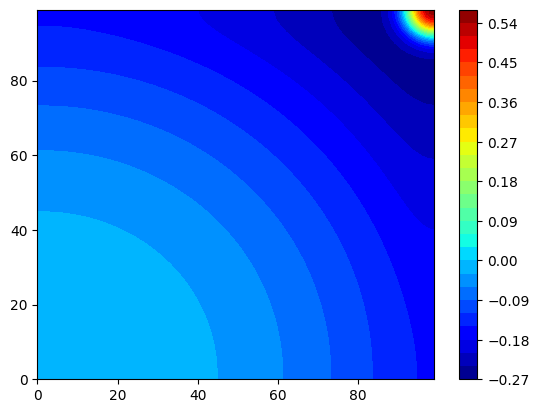

In [20]:

fig, ax = plt.subplots()
indices = np.where(np.isclose(t, 10))[0]
plt.contourf(u[indices].reshape(100,100), levels=30, cmap='jet')
plt.colorbar()

In [18]:
pinn = FitzHughNagumo(data_pts)

pinn.train()

torch.save(pinn.net.state_dict(), 'modelNN.pt')

tensor(0.1661, grad_fn=<AddBackward0>)
Iteration: 1, Loss: 0.166143
tensor(0.1444, grad_fn=<AddBackward0>)
Iteration: 2, Loss: 0.144380
tensor(0.1447, grad_fn=<AddBackward0>)
Iteration: 3, Loss: 0.144725
tensor(0.1482, grad_fn=<AddBackward0>)
Iteration: 4, Loss: 0.148232
tensor(0.1453, grad_fn=<AddBackward0>)
Iteration: 5, Loss: 0.145323
tensor(0.1409, grad_fn=<AddBackward0>)
Iteration: 6, Loss: 0.140941
tensor(0.1386, grad_fn=<AddBackward0>)
Iteration: 7, Loss: 0.138605
tensor(0.1385, grad_fn=<AddBackward0>)
Iteration: 8, Loss: 0.138549
tensor(0.1394, grad_fn=<AddBackward0>)
Iteration: 9, Loss: 0.139418
tensor(0.1398, grad_fn=<AddBackward0>)
Iteration: 10, Loss: 0.139839
tensor(0.1393, grad_fn=<AddBackward0>)
Iteration: 11, Loss: 0.139262
tensor(0.1379, grad_fn=<AddBackward0>)
Iteration: 12, Loss: 0.137939
tensor(0.1365, grad_fn=<AddBackward0>)
Iteration: 13, Loss: 0.136509
tensor(0.1356, grad_fn=<AddBackward0>)
Iteration: 14, Loss: 0.135587
tensor(0.1354, grad_fn=<AddBackward0>)
Iter

tensor(0.0342, grad_fn=<AddBackward0>)
Iteration: 174, Loss: 0.034239
tensor(0.0341, grad_fn=<AddBackward0>)
Iteration: 175, Loss: 0.034111
tensor(0.0338, grad_fn=<AddBackward0>)
Iteration: 176, Loss: 0.033847
tensor(0.0335, grad_fn=<AddBackward0>)
Iteration: 177, Loss: 0.033528
tensor(0.0331, grad_fn=<AddBackward0>)
Iteration: 178, Loss: 0.033114
tensor(0.0329, grad_fn=<AddBackward0>)
Iteration: 179, Loss: 0.032859
tensor(0.0328, grad_fn=<AddBackward0>)
Iteration: 180, Loss: 0.032775
tensor(0.0323, grad_fn=<AddBackward0>)
Iteration: 181, Loss: 0.032347
tensor(0.0321, grad_fn=<AddBackward0>)
Iteration: 182, Loss: 0.032114
tensor(0.0321, grad_fn=<AddBackward0>)
Iteration: 183, Loss: 0.032053
tensor(0.0317, grad_fn=<AddBackward0>)
Iteration: 184, Loss: 0.031665
tensor(0.0315, grad_fn=<AddBackward0>)
Iteration: 185, Loss: 0.031526
tensor(0.0314, grad_fn=<AddBackward0>)
Iteration: 186, Loss: 0.031363
tensor(0.0311, grad_fn=<AddBackward0>)
Iteration: 187, Loss: 0.031109
tensor(0.0310, grad_

Iteration: 318, Loss: 0.025299
tensor(0.0253, grad_fn=<AddBackward0>)
Iteration: 319, Loss: 0.025297
tensor(0.0253, grad_fn=<AddBackward0>)
Iteration: 320, Loss: 0.025265
tensor(0.0252, grad_fn=<AddBackward0>)
Iteration: 321, Loss: 0.025226
tensor(0.0252, grad_fn=<AddBackward0>)
Iteration: 322, Loss: 0.025209
tensor(0.0252, grad_fn=<AddBackward0>)
Iteration: 323, Loss: 0.025202
tensor(0.0252, grad_fn=<AddBackward0>)
Iteration: 324, Loss: 0.025180
tensor(0.0251, grad_fn=<AddBackward0>)
Iteration: 325, Loss: 0.025146
tensor(0.0251, grad_fn=<AddBackward0>)
Iteration: 326, Loss: 0.025120
tensor(0.0251, grad_fn=<AddBackward0>)
Iteration: 327, Loss: 0.025107
tensor(0.0251, grad_fn=<AddBackward0>)
Iteration: 328, Loss: 0.025091
tensor(0.0251, grad_fn=<AddBackward0>)
Iteration: 329, Loss: 0.025064
tensor(0.0250, grad_fn=<AddBackward0>)
Iteration: 330, Loss: 0.025035
tensor(0.0250, grad_fn=<AddBackward0>)
Iteration: 331, Loss: 0.025013
tensor(0.0250, grad_fn=<AddBackward0>)
Iteration: 332, Loss

Iteration: 463, Loss: 0.019701
tensor(0.0196, grad_fn=<AddBackward0>)
Iteration: 464, Loss: 0.019628
tensor(0.0196, grad_fn=<AddBackward0>)
Iteration: 465, Loss: 0.019554
tensor(0.0195, grad_fn=<AddBackward0>)
Iteration: 466, Loss: 0.019479
tensor(0.0194, grad_fn=<AddBackward0>)
Iteration: 467, Loss: 0.019404
tensor(0.0193, grad_fn=<AddBackward0>)
Iteration: 468, Loss: 0.019329
tensor(0.0193, grad_fn=<AddBackward0>)
Iteration: 469, Loss: 0.019255
tensor(0.0192, grad_fn=<AddBackward0>)
Iteration: 470, Loss: 0.019183
tensor(0.0191, grad_fn=<AddBackward0>)
Iteration: 471, Loss: 0.019117
tensor(0.0191, grad_fn=<AddBackward0>)
Iteration: 472, Loss: 0.019068
tensor(0.0191, grad_fn=<AddBackward0>)
Iteration: 473, Loss: 0.019053
tensor(0.0191, grad_fn=<AddBackward0>)
Iteration: 474, Loss: 0.019126
tensor(0.0194, grad_fn=<AddBackward0>)
Iteration: 475, Loss: 0.019380
tensor(0.0201, grad_fn=<AddBackward0>)
Iteration: 476, Loss: 0.020054
tensor(0.0212, grad_fn=<AddBackward0>)
Iteration: 477, Loss

Iteration: 608, Loss: 0.009509
tensor(0.0093, grad_fn=<AddBackward0>)
Iteration: 609, Loss: 0.009293
tensor(0.0092, grad_fn=<AddBackward0>)
Iteration: 610, Loss: 0.009157
tensor(0.0091, grad_fn=<AddBackward0>)
Iteration: 611, Loss: 0.009089
tensor(0.0091, grad_fn=<AddBackward0>)
Iteration: 612, Loss: 0.009075
tensor(0.0091, grad_fn=<AddBackward0>)
Iteration: 613, Loss: 0.009104
tensor(0.0092, grad_fn=<AddBackward0>)
Iteration: 614, Loss: 0.009175
tensor(0.0093, grad_fn=<AddBackward0>)
Iteration: 615, Loss: 0.009328
tensor(0.0096, grad_fn=<AddBackward0>)
Iteration: 616, Loss: 0.009580
tensor(0.0101, grad_fn=<AddBackward0>)
Iteration: 617, Loss: 0.010126
tensor(0.0109, grad_fn=<AddBackward0>)
Iteration: 618, Loss: 0.010878
tensor(0.0124, grad_fn=<AddBackward0>)
Iteration: 619, Loss: 0.012401
tensor(0.0132, grad_fn=<AddBackward0>)
Iteration: 620, Loss: 0.013168
tensor(0.0140, grad_fn=<AddBackward0>)
Iteration: 621, Loss: 0.013953
tensor(0.0116, grad_fn=<AddBackward0>)
Iteration: 622, Loss

...

tensor(5.4921e-06, grad_fn=<AddBackward0>)
Iteration: 22435, Loss: 0.000005
tensor(5.4911e-06, grad_fn=<AddBackward0>)
Iteration: 22436, Loss: 0.000005
tensor(5.4876e-06, grad_fn=<AddBackward0>)
Iteration: 22437, Loss: 0.000005
tensor(5.4871e-06, grad_fn=<AddBackward0>)
Iteration: 22438, Loss: 0.000005
tensor(5.4852e-06, grad_fn=<AddBackward0>)
Iteration: 22439, Loss: 0.000005
tensor(5.4848e-06, grad_fn=<AddBackward0>)
Iteration: 22440, Loss: 0.000005
tensor(5.4833e-06, grad_fn=<AddBackward0>)
Iteration: 22441, Loss: 0.000005
tensor(5.4829e-06, grad_fn=<AddBackward0>)
Iteration: 22442, Loss: 0.000005
tensor(5.4814e-06, grad_fn=<AddBackward0>)
Iteration: 22443, Loss: 0.000005
tensor(5.4807e-06, grad_fn=<AddBackward0>)
Iteration: 22444, Loss: 0.000005
tensor(5.4782e-06, grad_fn=<AddBackward0>)
Iteration: 22445, Loss: 0.000005
tensor(5.4773e-06, grad_fn=<AddBackward0>)
Iteration: 22446, Loss: 0.000005
tensor(5.4741e-06, grad_fn=<AddBackward0>)
Iteration: 22447, Loss: 0.000005
tensor(5.473

Iteration: 22579, Loss: 0.000005
tensor(5.1646e-06, grad_fn=<AddBackward0>)
Iteration: 22580, Loss: 0.000005
tensor(5.1636e-06, grad_fn=<AddBackward0>)
Iteration: 22581, Loss: 0.000005
tensor(5.1621e-06, grad_fn=<AddBackward0>)
Iteration: 22582, Loss: 0.000005
tensor(5.1612e-06, grad_fn=<AddBackward0>)
Iteration: 22583, Loss: 0.000005
tensor(5.1578e-06, grad_fn=<AddBackward0>)
Iteration: 22584, Loss: 0.000005
tensor(5.1569e-06, grad_fn=<AddBackward0>)
Iteration: 22585, Loss: 0.000005
tensor(5.1558e-06, grad_fn=<AddBackward0>)
Iteration: 22586, Loss: 0.000005
tensor(5.1519e-06, grad_fn=<AddBackward0>)
Iteration: 22587, Loss: 0.000005
tensor(5.1508e-06, grad_fn=<AddBackward0>)
Iteration: 22588, Loss: 0.000005
tensor(5.1496e-06, grad_fn=<AddBackward0>)
Iteration: 22589, Loss: 0.000005
tensor(5.1452e-06, grad_fn=<AddBackward0>)
Iteration: 22590, Loss: 0.000005
tensor(5.1441e-06, grad_fn=<AddBackward0>)
Iteration: 22591, Loss: 0.000005
tensor(5.1429e-06, grad_fn=<AddBackward0>)
Iteration: 2

tensor(4.8496e-06, grad_fn=<AddBackward0>)
Iteration: 22722, Loss: 0.000005
tensor(4.8452e-06, grad_fn=<AddBackward0>)
Iteration: 22723, Loss: 0.000005
tensor(4.8439e-06, grad_fn=<AddBackward0>)
Iteration: 22724, Loss: 0.000005
tensor(4.8412e-06, grad_fn=<AddBackward0>)
Iteration: 22725, Loss: 0.000005
tensor(4.8396e-06, grad_fn=<AddBackward0>)
Iteration: 22726, Loss: 0.000005
tensor(4.8375e-06, grad_fn=<AddBackward0>)
Iteration: 22727, Loss: 0.000005
tensor(4.8334e-06, grad_fn=<AddBackward0>)
Iteration: 22728, Loss: 0.000005
tensor(4.8310e-06, grad_fn=<AddBackward0>)
Iteration: 22729, Loss: 0.000005
tensor(4.8287e-06, grad_fn=<AddBackward0>)
Iteration: 22730, Loss: 0.000005
tensor(4.8252e-06, grad_fn=<AddBackward0>)
Iteration: 22731, Loss: 0.000005
tensor(4.8225e-06, grad_fn=<AddBackward0>)
Iteration: 22732, Loss: 0.000005
tensor(4.8193e-06, grad_fn=<AddBackward0>)
Iteration: 22733, Loss: 0.000005
tensor(4.8086e-06, grad_fn=<AddBackward0>)
Iteration: 22734, Loss: 0.000005
tensor(4.806

tensor(4.5526e-06, grad_fn=<AddBackward0>)
Iteration: 22868, Loss: 0.000005
tensor(4.5504e-06, grad_fn=<AddBackward0>)
Iteration: 22869, Loss: 0.000005
tensor(4.5495e-06, grad_fn=<AddBackward0>)
Iteration: 22870, Loss: 0.000005
tensor(4.5481e-06, grad_fn=<AddBackward0>)
Iteration: 22871, Loss: 0.000005
tensor(4.5467e-06, grad_fn=<AddBackward0>)
Iteration: 22872, Loss: 0.000005
tensor(4.5416e-06, grad_fn=<AddBackward0>)
Iteration: 22873, Loss: 0.000005
tensor(4.5403e-06, grad_fn=<AddBackward0>)
Iteration: 22874, Loss: 0.000005
tensor(4.5392e-06, grad_fn=<AddBackward0>)
Iteration: 22875, Loss: 0.000005
tensor(4.5376e-06, grad_fn=<AddBackward0>)
Iteration: 22876, Loss: 0.000005
tensor(4.5364e-06, grad_fn=<AddBackward0>)
Iteration: 22877, Loss: 0.000005
tensor(4.5335e-06, grad_fn=<AddBackward0>)
Iteration: 22878, Loss: 0.000005
tensor(4.5320e-06, grad_fn=<AddBackward0>)
Iteration: 22879, Loss: 0.000005
tensor(4.5307e-06, grad_fn=<AddBackward0>)
Iteration: 22880, Loss: 0.000005
tensor(4.527

Iteration: 23009, Loss: 0.000004
tensor(4.2992e-06, grad_fn=<AddBackward0>)
Iteration: 23010, Loss: 0.000004
tensor(4.2979e-06, grad_fn=<AddBackward0>)
Iteration: 23011, Loss: 0.000004
tensor(4.2959e-06, grad_fn=<AddBackward0>)
Iteration: 23012, Loss: 0.000004
tensor(4.2949e-06, grad_fn=<AddBackward0>)
Iteration: 23013, Loss: 0.000004
tensor(4.2914e-06, grad_fn=<AddBackward0>)
Iteration: 23014, Loss: 0.000004
tensor(4.2908e-06, grad_fn=<AddBackward0>)
Iteration: 23015, Loss: 0.000004
tensor(4.2904e-06, grad_fn=<AddBackward0>)
Iteration: 23016, Loss: 0.000004
tensor(4.2887e-06, grad_fn=<AddBackward0>)
Iteration: 23017, Loss: 0.000004
tensor(4.2882e-06, grad_fn=<AddBackward0>)
Iteration: 23018, Loss: 0.000004
tensor(4.2877e-06, grad_fn=<AddBackward0>)
Iteration: 23019, Loss: 0.000004
tensor(4.2872e-06, grad_fn=<AddBackward0>)
Iteration: 23020, Loss: 0.000004
tensor(4.2852e-06, grad_fn=<AddBackward0>)
Iteration: 23021, Loss: 0.000004
tensor(4.2844e-06, grad_fn=<AddBackward0>)
Iteration: 2

In [21]:
## Testing Data
idx = np.where(np.isclose(t, 2.020202))[0]
print(idx)
t_test = t[idx]
x_test = x[idx]
y_test = y[idx]

[    20    120    220 ... 999720 999820 999920]


In [22]:
print(t_test.shape)

(10000, 1)


Text(0, 0.5, 'y')

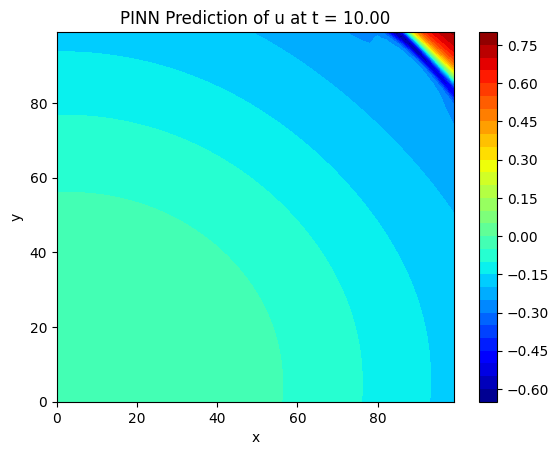

In [23]:
pinn2 = FitzHughNagumo(data_pts)
pinn2.net.load_state_dict(torch.load('modelNN.pt'))
pinn2.net.eval()

x_test = torch.tensor(x_test, dtype=torch.float32, requires_grad=True)
y_test = torch.tensor(y_test, dtype=torch.float32, requires_grad=True)
t_test = torch.tensor(np.full((10000,1), 10), dtype=torch.float32, requires_grad=True)

u_out, v_out = pinn2.function(x_test, y_test, t_test)


u_plot = u_out.data.cpu().numpy()
u_plot = np.reshape(u_plot, (100, 100))
time_val = t_test[0].item()
fig, ax = plt.subplots()

plt.contourf(u_plot, levels=30, cmap='jet')
plt.colorbar()

plt.title(f"PINN Prediction of u at t = {time_val:.2f}")
plt.xlabel("x")
plt.ylabel("y")



In [22]:
import imageio
import os

In [23]:
def generate_u_gif(
    pinn,
    x_flat,
    y_flat,
    t_min,
    t_max,
    Nt=50,
    filename="u_prediction.gif",
    levels=30,
    cmap="jet"
):
    """
    Generate a GIF of u(x,y,t) predicted by a trained PINN.

    Parameters
    ----------
    pinn : FitzHughNagumo
        Trained PINN model (with loaded weights)
    x_grid, y_grid : np.ndarray
        Meshgrid arrays of shape (Nx, Ny)
    t_min, t_max : float
        Time range
    Nt : int
        Number of time frames
    filename : str
        Output GIF filename
    """

    pinn.net.eval()

    Nx, Ny = 100,100
    frames = []

    for t_val in np.linspace(t_min, t_max, Nt):
        t_test = np.full((10000,1), t_val)
        t_flat = torch.tensor(t_test, dtype=torch.float32, requires_grad=True)


        u_pred, _ = pinn.function(x_flat, y_flat, t_flat)

        # Reshape to grid
        u_plot = u_pred.data.cpu().numpy().reshape(Nx, Ny)

        # Plot
        fig, ax = plt.subplots(figsize=(5, 4))
        vmin, vmax = -1.0, 1.5
        contour = ax.contourf(u_plot, levels=levels, cmap=cmap)
        ax.set_title(f"u(x,y,t), t = {t_val:.3f}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        fig.colorbar(contour)

        # Save frame to buffer
        fig.canvas.draw()
        buf = np.asarray(fig.canvas.buffer_rgba())
        image = buf[..., :3]
        frames.append(image)
        plt.close(fig)

    # Save GIF
    imageio.mimsave(filename, frames, fps=8)

    print(f"GIF saved to {filename}")


In [24]:
generate_u_gif(pinn2, x_test, y_test, 0, 20, 100, "nn_prediction.gif", 30, "jet")

GIF saved to nn_prediction.gif


In [49]:
!pip install imageio

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com

[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python -m pip install --upgrade pip


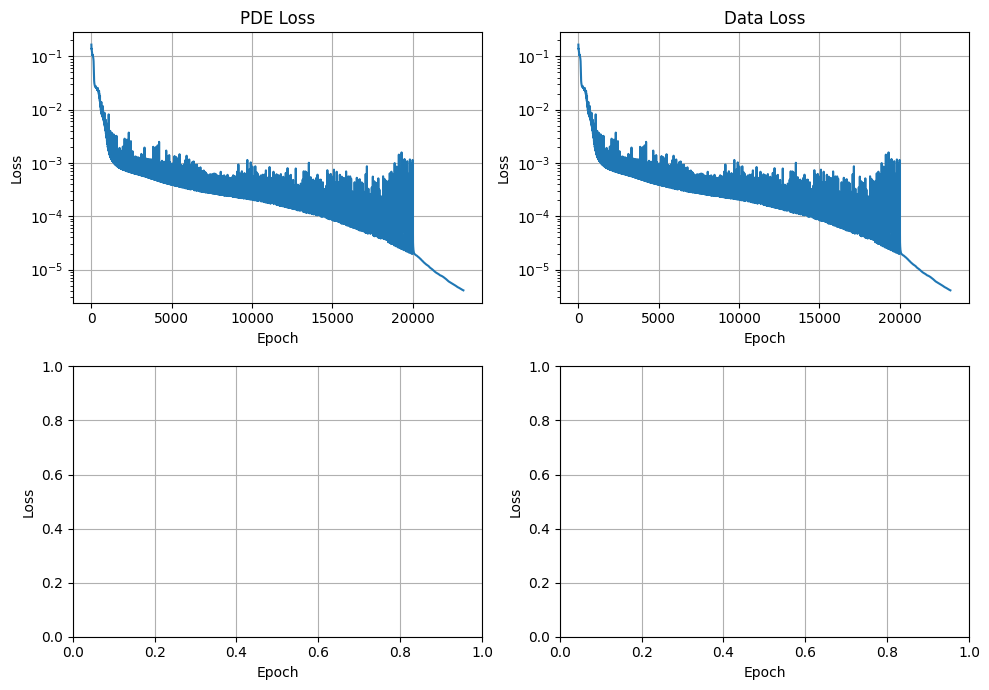

In [25]:
fig, axs = plt.subplots(2, 2, figsize=(10,7))

axs[0,0].plot(pinn.losses)
axs[0,0].set_title("PDE Loss")
axs[0,0].set_yscale("log")

axs[0,1].plot(pinn.data_losses)
axs[0,1].set_title("Data Loss")
axs[0,1].set_yscale("log")

# axs[1,0].plot(pinn.ic_losses)
# axs[1,0].set_title("IC Loss")
# axs[1,0].set_yscale("log")

# axs[1,1].plot(pinn.bc_losses)
# axs[1,1].set_title("BC Loss")
# axs[1,1].set_yscale("log")

for ax in axs.flat:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [26]:
print(pinn.pde_losses)

AttributeError: 'FitzHughNagumo' object has no attribute 'pde_losses'

Timestep t = 8.00
Relative L2 Error: 0.185543
RMSE: 0.062545
MAE: 0.021846
Accuracy (1 - rel L2): 0.814457


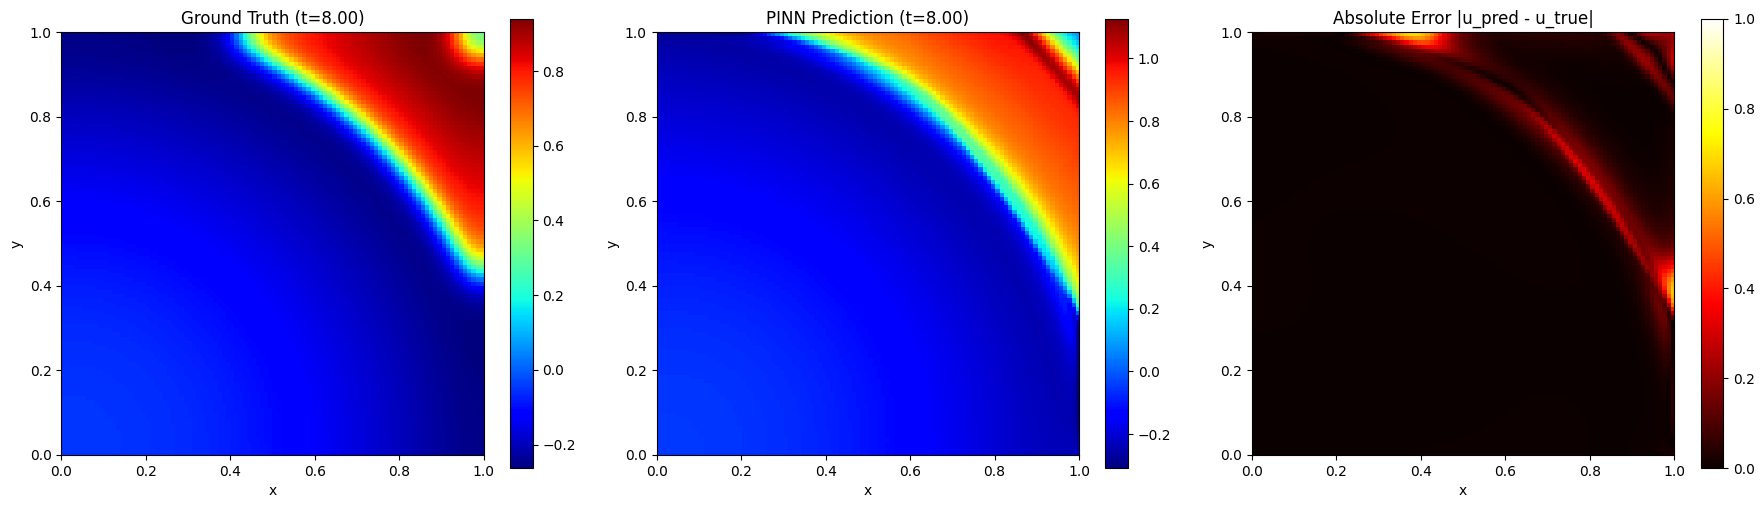

In [32]:
# choose timestep index
t_index = 80
time_val = t_index / 10

# ground truth
u_true = training_points[t_index, :, :]

# create grid
x = np.linspace(0,1,100)
y = np.linspace(0,1,100)
X, Y = np.meshgrid(x,y)

# flatten grid for PINN
x_test = torch.tensor(X.flatten()[:,None], dtype=torch.float32, requires_grad=True)
y_test = torch.tensor(Y.flatten()[:,None], dtype=torch.float32, requires_grad=True)
t_test = torch.tensor(np.full_like(X.flatten()[:,None], time_val), dtype=torch.float32, requires_grad=True)

# PINN prediction
u_out, v_out = pinn2.function(x_test, y_test, t_test)
u_pred = u_out.detach().cpu().numpy().reshape(100,100)

# error
error = np.abs(u_true - u_pred)

# ===== METRICS =====
# Relative L2 Error
rel_l2_error = np.linalg.norm(u_true - u_pred) / np.linalg.norm(u_true)

# RMSE
rmse = np.sqrt(np.mean((u_true - u_pred)**2))

# MAE
mae = np.mean(np.abs(u_true - u_pred))

# "Accuracy" (optional interpretation)
accuracy = 1 - rel_l2_error

print(f"Timestep t = {time_val:.2f}")
print(f"Relative L2 Error: {rel_l2_error:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"MAE: {mae:.6f}")
print(f"Accuracy (1 - rel L2): {accuracy:.6f}")

# ===== PLOTTING =====
fig, axs = plt.subplots(1,3, figsize=(18,5))

# ground truth
gt = axs[0].imshow(u_true, cmap='jet', origin='lower', extent=[0,1,0,1])
axs[0].set_title(f"Ground Truth (t={time_val:.2f})")
fig.colorbar(gt, ax=axs[0])

# prediction
pred = axs[1].imshow(u_pred, cmap='jet', origin='lower', extent=[0,1,0,1])
axs[1].set_title(f"PINN Prediction (t={time_val:.2f})")
fig.colorbar(pred, ax=axs[1])

# error
err = axs[2].imshow(error, cmap='hot', origin='lower', extent=[0,1,0,1],vmin=0, vmax=1.0)
axs[2].set_title("Absolute Error |u_pred - u_true|")
fig.colorbar(err, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()